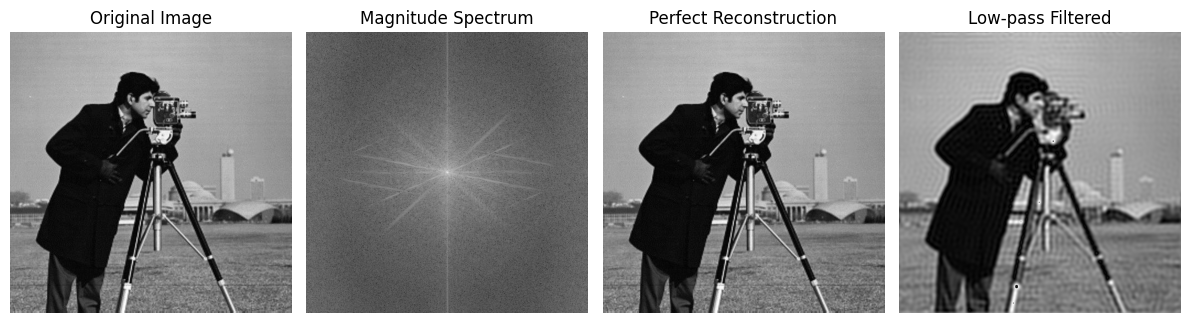

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def fft_pipeline(image_path, low_pass_size=30):
    # image in grayscale
    img = cv2.imread(image_path, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        print("Error: Image not found!")
        return

    # Compute 2D Fourier Transform
    f = np.fft.fft2(img)
    fshift = np.fft.fftshift(f)  # Shift zero freq to center

    # Magnitude spectrum (log scale)
    magnitude_spectrum = 20 * np.log(np.abs(fshift) + 1)  # +1 to avoid log(0)

    # Perfect reconstruction
    img_reconstructed = np.fft.ifft2(np.fft.ifftshift(fshift))
    img_reconstructed = np.abs(img_reconstructed).astype(np.uint8)

    # Low-pass filter
    rows, cols = img.shape
    crow, ccol = rows // 2, cols // 2

    # Create a circular mask for low-pass filtering
    mask = np.zeros((rows, cols), np.uint8)
    y, x = np.ogrid[:rows, :cols]
    mask_area = (x - ccol)**2 + (y - crow)**2 <= low_pass_size**2
    mask[mask_area] = 1

    # Apply mask in frequency domain
    fshift_filtered = fshift * mask
    img_lowpass = np.fft.ifft2(np.fft.ifftshift(fshift_filtered))
    img_lowpass = np.abs(img_lowpass).astype(np.uint8)

    # Display results
    plt.figure(figsize=(12, 6))

    plt.subplot(1, 4, 1)
    plt.imshow(img, cmap='gray')
    plt.title('Original Image')
    plt.axis('off')

    plt.subplot(1, 4, 2)
    plt.imshow(magnitude_spectrum, cmap='gray')
    plt.title('Magnitude Spectrum')
    plt.axis('off')

    plt.subplot(1, 4, 3)
    plt.imshow(img_reconstructed, cmap='gray')
    plt.title('Perfect Reconstruction')
    plt.axis('off')

    plt.subplot(1, 4, 4)
    plt.imshow(img_lowpass, cmap='gray')
    plt.title('Low-pass Filtered')
    plt.axis('off')

    plt.tight_layout()
    plt.show()


fft_pipeline("CameraMan.jpg", low_pass_size=50)
